# Photon Blockade — Driven Jaynes-Cummings Model

In [ ]:
!pip install qutip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.1/33.1 MB 46.9 MB/s eta 0:00:00


## Imports and shared parameters

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.special import factorial
import qutip as qt

N     = 50       # Fock space truncation
kappa = 0.1      # Cavity decay rate
Gamma = 0.05     # Atomic spontaneous emission rate
g     = 5.0      # JC coupling  (strong: g/kappa = 50)

#operators define at first
a     = qt.tensor(qt.destroy(N), qt.qeye(2))
n_op  = a.dag() * a
n_nm1 = a.dag() * a.dag() * a * a          # n(n-1)  for g^(2)
sm    = qt.tensor(qt.qeye(N), qt.sigmam())
sp    = sm.dag()
Pe    = qt.tensor(qt.qeye(N), qt.ket2dm(qt.basis(2, 0)))   # |e><e|

c_ops = [np.sqrt(kappa) * a, np.sqrt(Gamma) * sm]

#definitions needed
def build_H(Delta, g_val, E):
    """Rotating-frame Hamiltonian at detuning Delta, coupling g_val, drive E."""
    return (Delta * n_op
          + Delta * Pe
          + g_val * (sp * a + sm * a.dag())
          + E     * (a + a.dag()))
def g2_steadystate(H):
    rho   = qt.steadystate(H, c_ops)
    n_ss  = qt.expect(n_op,   rho).real
    nm1   = qt.expect(n_nm1,  rho).real
    g2    = nm1 / n_ss**2 if n_ss > 1e-12 else 0.0
    return rho, n_ss, g2

print(f"QuTiP version : {qt.__version__}")
print(f"N={N}, kappa={kappa}, Gamma={Gamma}, g={g}")
print(f"Strong coupling ratio g/kappa = {g/kappa:.0f}")
print(f"Blockade gap = g*(sqrt(2)-1) = {g*(np.sqrt(2)-1):.3f}  vs linewidth kappa/2 = {kappa/2:.3f}")

QuTiP version : 5.2.3
N=50, kappa=0.1, Gamma=0.05, g=5.0
Strong coupling ratio g/kappa = 50
Blockade gap = g*(sqrt(2)-1) = 2.071  vs linewidth kappa/2 = 0.050


---
## Part 1 — Steady state: `g=0`, resonance drive

**Parameter choice:** $E=1.0$, $\kappa=0.5$ gives $\langle\hat{n}\rangle_\text{ss} = (E/\kappa)^2 = 4 \leq 10$.  
Poisson distribution with mean 4 has $P(n>15) < 10^{-6}$, so $N=50$.

With $\tilde{g}=0$ and $\Delta=0$: $\hat{H}' = E(\hat{a}+\hat{a}^\dagger)$.  
Exact steady state is a **coherent state** $|\alpha_\text{ss}\rangle$ with $|\alpha|^2 = (E/\kappa)^2$.

/usr/local/lib/python3.12/dist-packages/qutip/solver/options.py:16: FutureWarning: Dedicated options class are no longer needed, options should be passed as dict to solvers.
  warnings.warn(


Mean photon number
Numerical  <n>_ss = 16.000000
Analytic   <n>_ss = 16.000000  [(E/kappa)^2]


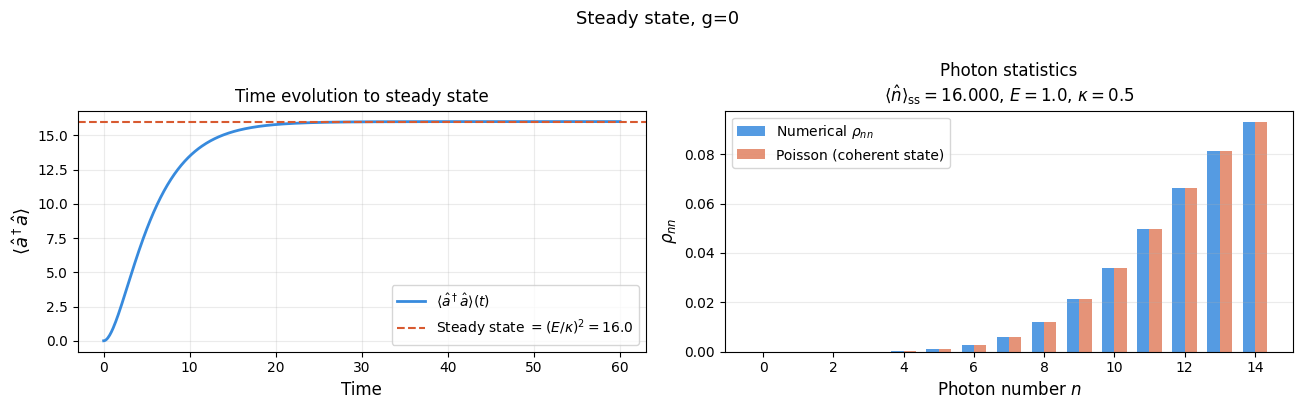

In [ ]:
E_ss    = 1.0
kappa_ss = 0.5    # larger kappa so <n>_ss = (E/kappa)^2 = 4

c_ops_ss = [np.sqrt(kappa_ss) * a, np.sqrt(Gamma) * sm]

H_ss  = E_ss * (a + a.dag())   # g=0, Delta=0
rho0  = qt.ket2dm(qt.tensor(qt.basis(N, 0), qt.basis(2, 1)))  # |g,0>
tlist = np.linspace(0, 60, 600)

#solving the Lindbald master eq after RWA and condtiotions
result = qt.mesolve(H_ss, rho0, tlist,
                    c_ops=c_ops_ss,
                    e_ops=[n_op],
                    options=qt.Options(nsteps=10000))
n_t = result.expect[0]

# to find mean photon number
rho_ss_g0    = qt.steadystate(H_ss, c_ops_ss)
n_ss_num     = qt.expect(n_op, rho_ss_g0).real
n_ss_analytic = 4*(E_ss / kappa_ss)**2

#photon number distribution
rho_cav_g0 = rho_ss_g0.ptrace(0)
ns         = np.arange(N)
rho_nn_g0  = np.array([rho_cav_g0[k, k].real for k in ns])
poisson_g0 = np.exp(-n_ss_analytic) * n_ss_analytic**ns / factorial(ns)

print(f"Mean photon number")
print(f"Numerical  <n>_ss = {n_ss_num:.6f}")
print(f"Analytic   <n>_ss = {n_ss_analytic:.6f}  [(E/kappa)^2]")

#plot
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
#steady state
ax = axes[0]
ax.plot(tlist, n_t, color='#378ADD', lw=2,
        label=r'$\langle\hat{a}^\dagger\hat{a}\rangle(t)$')
ax.axhline(n_ss_analytic, color='#D85A30', lw=1.5, ls='--',
           label=rf'Steady state $= (E/\kappa)^2 = {n_ss_analytic:.1f}$')
ax.set_xlabel('Time', fontsize=12)
ax.set_ylabel(r'$\langle\hat{a}^\dagger\hat{a}\rangle$', fontsize=13)
ax.set_title('Time evolution to steady state', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.25)
#occupation vs coherent state
ax = axes[1]
w  = 0.35
ax.bar(ns[:15] - w/2, rho_nn_g0[:15],  width=w, color='#378ADD',
       alpha=0.85, label=r'Numerical $\rho_{nn}$')
ax.bar(ns[:15] + w/2, poisson_g0[:15], width=w, color='#D85A30',
       alpha=0.65, label=r'Poisson (coherent state)')
ax.set_xlabel('Photon number $n$', fontsize=12)
ax.set_ylabel(r'$\rho_{nn}$', fontsize=12)
ax.set_title(
    f'Photon statistics\n'
    rf'$\langle\hat{{n}}\rangle_\mathrm{{ss}}={n_ss_num:.3f}$, '
    rf'$E={E_ss}$, $\kappa={kappa_ss}$', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.25, axis='y')

plt.suptitle('Steady state, g=0', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('part1_steady_state.png', dpi=120, bbox_inches='tight')
plt.show()

---
## Part 2 — Photon blockade: `g>0`, one-photon dressed state resonance

Drive set to lower polariton: $\omega = \omega_c - \tilde{g}$ ⟹ $\Delta = \tilde{g}$.

**Strong coupling condition:** $\tilde{g} = 5 \gg \kappa = 0.1, \Gamma = 0.05$  
**Weak drive condition:** $E \ll \kappa$

**Mandel Q parameter:** $Q = (\langle\hat{n}^2\rangle - \langle\hat{n}\rangle^2)/\langle\hat{n}\rangle - 1$
- $Q < 0$: sub-Poissonian → blockade active  
- $Q = 0$: Poissonian → coherent state  
- $Q > 0$: super-Poissonian → overdrive / bistability

In [ ]:
# To see the steady state density matrix for the weakest drive
E_weak = 0.05
H_weak = build_H(g, g, E_weak)
rho_weak = qt.steadystate(H_weak, c_ops)

# Print the most significant diagonal elements- gives population
print(f"Steady State Populations for E={E_weak}:")
# Extracting the diagonal of the density matrix
diag = rho_weak.diag()

# Map the flat index back to (photon_number, atom_state)
print(f"  P(0 photons, ground state): {diag[1]:.6f}")
print(f"  P(1 photon,  ground state): {diag[3]:.6f}")
print(f"  P(0 photons, excited state): {diag[0]:.6f}")
print(f"  P(Total > 1 photon): {1 - (diag[0]+diag[1]+diag[3]):.6e}")

Steady State Populations for E=0.05:
  P(0 photons, ground state): 0.679802
  P(1 photon,  ground state): 0.160062
  P(0 photons, excited state): 0.160000
  P(Total > 1 photon): 1.358816e-04


--- Logging error ---
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/tornado/ioloop.py", line 758, in _run_callback
    ret = callback()
          ^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/ipykernel/iostream.py", line 518, in _flush
    self.session.send(
  File "/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py", line 820, in send
    msg = self.msg(
          ^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py", line 661, in msg
    header = self.msg_header(msg_type) if header is None else header
             ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py", line 644, in msg_header
    return msg_header(self.msg_id, msg_type, self.username, self.session)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py", line 275, in msg_header
    date

  2.00     0.74062    -0.04265   0.46757   0.36600


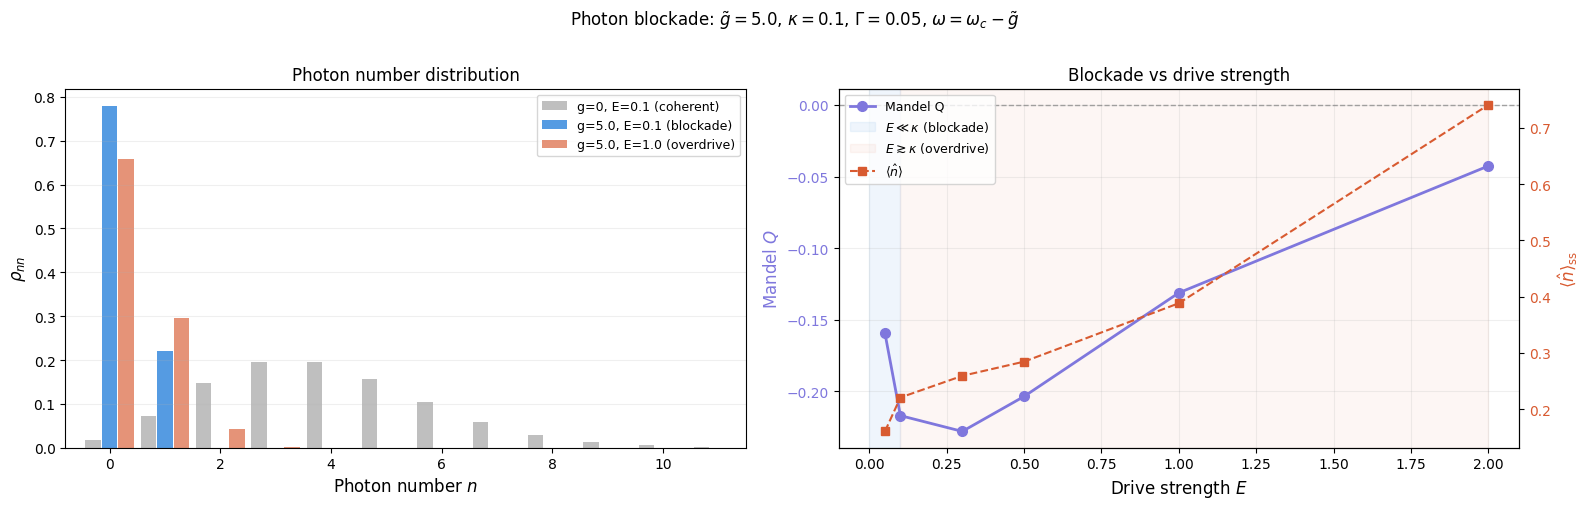

In [ ]:
E_list = [0.05, 0.1, 0.3, 0.5, 1.0, 2.0]

# here for this exefcise the Reference: g=0
H_ref     = build_H(0.0, 0.0, 0.1)
rho_ref   = qt.steadystate(H_ref, c_ops)
rc_ref    = rho_ref.ptrace(0)
n_ref     = qt.expect(n_op, rho_ref).real
rho_nn_ref = np.array([rc_ref[k, k].real for k in range(N)])

# Scan over E with blockade Hamiltonian (Delta = g)
blk_results = {}
print(f"{'E':>6}  {'<n>':>10}  {'Q':>10}  {'rho_00':>8}  {'rho_11':>8}")
for E in E_list:
    H        = build_H(g, g, E)       # Delta = g => lower polariton resonance
    rho_ss   = qt.steadystate(H, c_ops)
    rho_cav  = rho_ss.ptrace(0)
    n_ss     = qt.expect(n_op,           rho_ss).real
    n2_ss    = qt.expect(n_op * n_op,    rho_ss).real
    Q_ss     = (n2_ss - n_ss**2) / n_ss - 1 if n_ss > 1e-10 else 0.0
    rho_nn   = np.array([rho_cav[k, k].real for k in range(N)])
    blk_results[E] = {'n': n_ss, 'Q': Q_ss, 'rho_nn': rho_nn}
    print(f"{E:>6.2f}  {n_ss:>10.5f}  {Q_ss:>10.5f}  "
          f"{rho_nn[0]:>8.5f}  {rho_nn[1]:>8.5f}")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ns = np.arange(12)

# Panel 1: three representative distributions
ax = axes[0]
ax.bar(ns - 0.3, rho_nn_ref[:12],          width=0.28, color='gray',
       alpha=0.5, label='g=0, E=0.1 (coherent)')
ax.bar(ns,       blk_results[0.1]['rho_nn'][:12], width=0.28, color='#378ADD',
       alpha=0.85, label=f'g={g}, E=0.1 (blockade)')
ax.bar(ns + 0.3, blk_results[1.0]['rho_nn'][:12], width=0.28, color='#D85A30',
       alpha=0.65, label=f'g={g}, E=1.0 (overdrive)')
ax.set_xlabel('Photon number $n$', fontsize=12)
ax.set_ylabel(r'$\rho_{nn}$', fontsize=12)
ax.set_title('Photon number distribution', fontsize=12)
ax.legend(fontsize=9); ax.grid(True, alpha=0.2, axis='y')
ax.set_xlim(-0.8, 11.5)

# Panel 2: Mandel Q and <n> vs E
ax  = axes[1]
ax2 = ax.twinx()
E_arr = np.array(E_list)
Q_arr = np.array([blk_results[E]['Q'] for E in E_list])
n_arr = np.array([blk_results[E]['n'] for E in E_list])
ax.plot(E_arr, Q_arr, 'o-', color='#7F77DD', lw=2, ms=7, label='Mandel Q')
ax.axhline(0, color='gray', lw=1, ls='--', alpha=0.7)
ax2.plot(E_arr, n_arr, 's--', color='#D85A30', lw=1.5, ms=6,
         label=r'$\langle\hat{n}\rangle$')
ax.axvspan(0, kappa, color='#378ADD', alpha=0.08, label=r'$E\ll\kappa$ (blockade)')
ax.axvspan(kappa, max(E_list), color='#D85A30', alpha=0.05,
           label=r'$E\gtrsim\kappa$ (overdrive)')
ax.set_xlabel('Drive strength $E$', fontsize=12)
ax.set_ylabel('Mandel $Q$', fontsize=12, color='#7F77DD')
ax2.set_ylabel(r'$\langle\hat{n}\rangle_\mathrm{ss}$', fontsize=12, color='#D85A30')
ax.set_title('Blockade vs drive strength', fontsize=12)
ax.tick_params(axis='y', labelcolor='#7F77DD')
ax2.tick_params(axis='y', labelcolor='#D85A30')
l1, b1 = ax.get_legend_handles_labels()
l2, b2 = ax2.get_legend_handles_labels()
ax.legend(l1+l2, b1+b2, fontsize=9, loc='upper left')
ax.grid(True, alpha=0.2)

plt.suptitle(
    rf'Photon blockade: $\tilde{{g}}={g}$, $\kappa={kappa}$, '
    rf'$\Gamma={Gamma}$, $\omega=\omega_c-\tilde{{g}}$',
    fontsize=12, y=1.01)
plt.tight_layout()
#plt.savefig('part2_photon_blockade.png', dpi=120, bbox_inches='tight')
plt.show()

---
## Two-photon correlation function $g^{(2)}(0)$

$$g^{(2)}(0) = \frac{\langle\hat{a}^\dagger\hat{a}^\dagger\hat{a}\hat{a}\rangle}{\langle\hat{a}^\dagger\hat{a}\rangle^2} = \frac{\langle\hat{n}(\hat{n}-1)\rangle}{\langle\hat{n}\rangle^2}$$

--- Logging error ---
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/tornado/ioloop.py", line 758, in _run_callback
    ret = callback()
          ^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/ipykernel/iostream.py", line 518, in _flush
    self.session.send(
  File "/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py", line 820, in send
    msg = self.msg(
          ^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py", line 661, in msg
    header = self.msg_header(msg_type) if header is None else header
             ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py", line 644, in msg_header
    return msg_header(self.msg_id, msg_type, self.username, self.session)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py", line 275, in msg_header
    date

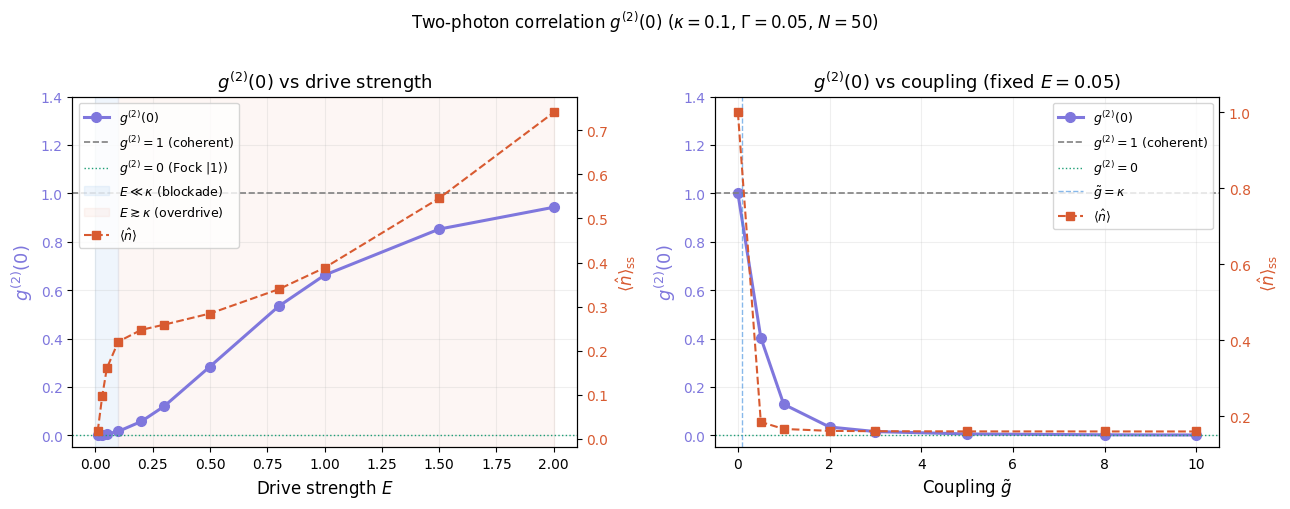

In [ ]:
E_scan = [0.01, 0.03, 0.05, 0.1, 0.2, 0.3, 0.5, 0.8, 1.0, 1.5, 2.0]

# g2 reference (g=0)
_, n_ref_g2, g2_ref_val = g2_steadystate(build_H(0.0, 0.0, 0.1))
print(f"Reference g=0: g^(2) = {g2_ref_val:.6f}  (expect 1.0)")

# Scan E at fixed g (blockade Hamiltonian, Delta=g)
g2_vs_E, n_vs_E = [], []
for E in E_scan:
    _, n_ss, g2 = g2_steadystate(build_H(g, g, E))
    g2_vs_E.append(g2); n_vs_E.append(n_ss)

# Scan g at fixed weak E
g_scan   = [0.0, 0.5, 1.0, 2.0, 3.0, 5.0, 8.0, 10.0]
E_fixed  = 0.05
g2_vs_g, n_vs_g = [], []
for gv in g_scan:
    Delta = gv if gv > 0 else 0.0
    _, n_ss, g2 = g2_steadystate(build_H(Delta, gv, E_fixed))
    g2_vs_g.append(g2); n_vs_g.append(n_ss)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
E_arr = np.array(E_scan)
g_arr = np.array(g_scan)

ax  = axes[0]
ax2 = ax.twinx()
ax.plot(E_arr, g2_vs_E, 'o-', color='#7F77DD', lw=2.2, ms=7,
        label=r'$g^{(2)}(0)$')
ax.axhline(1.0, color='gray',    lw=1.2, ls='--', label=r'$g^{(2)}=1$ (coherent)')
ax.axhline(0.0, color='#1D9E75', lw=1.0, ls=':',  label=r'$g^{(2)}=0$ (Fock $|1\rangle$)')
ax2.plot(E_arr, n_vs_E, 's--', color='#D85A30', lw=1.5, ms=6,
         label=r'$\langle\hat{n}\rangle$')
ax.axvspan(0,     kappa,        color='#378ADD', alpha=0.08,
           label=r'$E\ll\kappa$ (blockade)')
ax.axvspan(kappa, max(E_scan),  color='#D85A30', alpha=0.05,
           label=r'$E\gtrsim\kappa$ (overdrive)')
ax.set_xlabel('Drive strength $E$', fontsize=12)
ax.set_ylabel(r'$g^{(2)}(0)$', fontsize=13, color='#7F77DD')
ax2.set_ylabel(r'$\langle\hat{n}\rangle_\mathrm{ss}$', fontsize=12, color='#D85A30')
ax.set_title(r'$g^{(2)}(0)$ vs drive strength', fontsize=13)
ax.tick_params(axis='y', labelcolor='#7F77DD')
ax2.tick_params(axis='y', labelcolor='#D85A30')
ax.set_ylim(-0.05, 1.4)
l1,b1 = ax.get_legend_handles_labels()
l2,b2 = ax2.get_legend_handles_labels()
ax.legend(l1+l2, b1+b2, fontsize=9, loc='upper left')
ax.grid(True, alpha=0.2)

ax  = axes[1]
ax2 = ax.twinx()
ax.plot(g_arr, g2_vs_g, 'o-', color='#7F77DD', lw=2.2, ms=7,
        label=r'$g^{(2)}(0)$')
ax.axhline(1.0, color='gray',    lw=1.2, ls='--', label=r'$g^{(2)}=1$ (coherent)')
ax.axhline(0.0, color='#1D9E75', lw=1.0, ls=':',  label=r'$g^{(2)}=0$')
ax.axvline(kappa, color='#378ADD', lw=1.0, ls='--', alpha=0.6,
           label=r'$\tilde{g}=\kappa$')
ax2.plot(g_arr, n_vs_g, 's--', color='#D85A30', lw=1.5, ms=6,
         label=r'$\langle\hat{n}\rangle$')
ax.set_xlabel(r'Coupling $\tilde{g}$', fontsize=12)
ax.set_ylabel(r'$g^{(2)}(0)$', fontsize=13, color='#7F77DD')
ax2.set_ylabel(r'$\langle\hat{n}\rangle_\mathrm{ss}$', fontsize=12, color='#D85A30')
ax.set_title(rf'$g^{{(2)}}(0)$ vs coupling (fixed $E={E_fixed}$)', fontsize=13)
ax.tick_params(axis='y', labelcolor='#7F77DD')
ax2.tick_params(axis='y', labelcolor='#D85A30')
ax.set_ylim(-0.05, 1.4)
l1,b1 = ax.get_legend_handles_labels()
l2,b2 = ax2.get_legend_handles_labels()
ax.legend(l1+l2, b1+b2, fontsize=9, loc='upper right')
ax.grid(True, alpha=0.2)

plt.suptitle(
    rf'Two-photon correlation $g^{{(2)}}(0)$'
    rf' ($\kappa={kappa}$, $\Gamma={Gamma}$, $N={N}$)',
    fontsize=12, y=1.01)
plt.tight_layout()
#plt.savefig('part3_g2.png', dpi=120, bbox_inches='tight')
plt.show()

---
##frequency scan

Scan probe frequency $\omega$ across the vacuum Rabi doublet.  
Detuning: $\Delta = \omega_c - \omega$, swept over $[-2\tilde{g},\, +2\tilde{g}]$.

**Expected features:**
- Transmission peaks at $\Delta = \pm\tilde{g}$ (polariton resonances)
- $g^{(2)} < 1$ at the polariton peaks (antibunching / blockade)
- $g^{(2)} > 1$ near $\Delta = \pm\tilde{g}/\sqrt{2}$ (two-photon resonance, bunching)
- $g^{(2)} \approx 1$ far from resonance

--- Logging error ---
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/tornado/ioloop.py", line 758, in _run_callback
    ret = callback()
          ^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/ipykernel/iostream.py", line 518, in _flush
    self.session.send(
  File "/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py", line 820, in send
    msg = self.msg(
          ^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py", line 661, in msg
    header = self.msg_header(msg_type) if header is None else header
             ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py", line 644, in msg_header
    return msg_header(self.msg_id, msg_type, self.username, self.session)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py", line 275, in msg_header
    date

Done.  Peak transmission at Delta=4.983
Min g^(2) = 0.0062 at Delta=-4.983


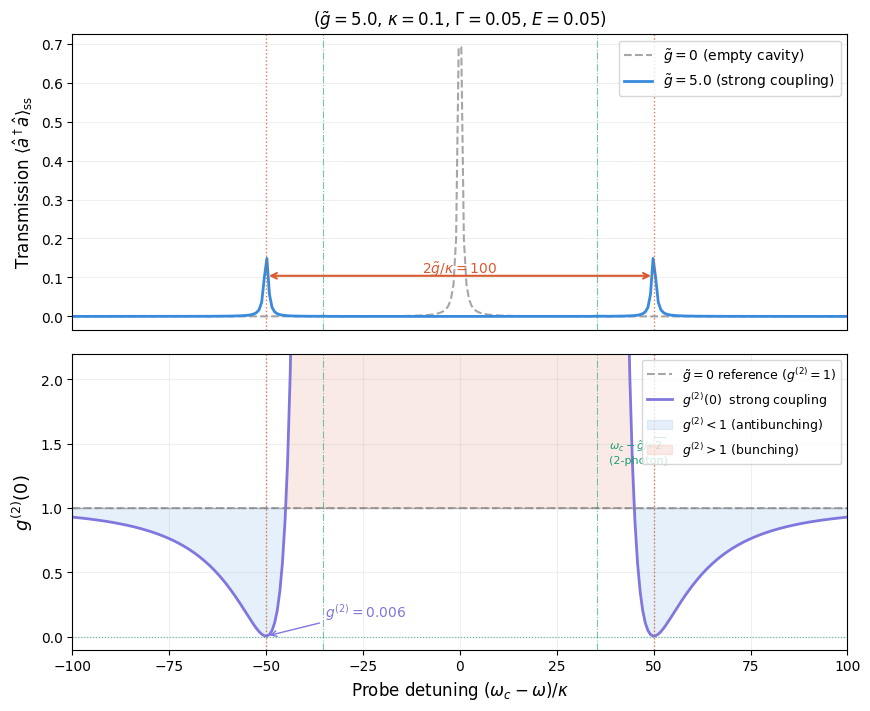

In [ ]:
E_probe   = 0.05
n_pts     = 300
Delta_arr = np.linspace(-2*g, 2*g, n_pts)

T_arr  = np.zeros(n_pts)
g2_arr = np.zeros(n_pts)
T_ref  = np.zeros(n_pts)
g2_ref = np.zeros(n_pts)

print(f"Scanning {n_pts} frequency points (E={E_probe}, g={g}) ...")
for i, Delta in enumerate(Delta_arr):
    # With coupling
    rho_ss, n_ss, g2 = g2_steadystate(build_H(Delta, g, E_probe))
    T_arr[i]  = n_ss
    g2_arr[i] = g2
    # Without coupling (reference)
    rho_r, n_r, g2_r = g2_steadystate(build_H(Delta, 0.0, E_probe))
    T_ref[i]  = n_r
    g2_ref[i] = g2_r if n_r > 1e-12 else 1.0

print(f"Done.  Peak transmission at Delta={Delta_arr[np.argmax(T_arr)]:.3f}")
print(f"Min g^(2) = {np.min(g2_arr):.4f} at Delta={Delta_arr[np.argmin(g2_arr)]:.3f}")

# Plot
x   = Delta_arr / kappa    # x-axis in units of kappa
fig = plt.figure(figsize=(10, 8))
gs2 = gridspec.GridSpec(2, 1, figure=fig, hspace=0.08)

# Top panel: transmission
ax1 = fig.add_subplot(gs2[0])
ax1.plot(x, T_ref,  color='gray',    lw=1.5, ls='--', alpha=0.7,
         label=r'$\tilde{g}=0$ (empty cavity)')
ax1.plot(x, T_arr,  color='#378ADD', lw=2.0,
         label=rf'$\tilde{{g}}={g}$ (strong coupling)')
for xpk, lbl in [(+g/kappa, r'$\omega_c-\tilde{g}$'),
                  (-g/kappa, r'$\omega_c+\tilde{g}$')]:
    ax1.axvline(xpk, color='#D85A30', lw=1.0, ls=':', alpha=0.8)
for sign in [+1, -1]:
    ax1.axvline(sign*g/(np.sqrt(2)*kappa),
                color='#1D9E75', lw=0.8, ls='-.', alpha=0.6)
ymax = np.max(T_arr)
ax1.annotate('',
    xy=( g/kappa, ymax*0.7), xytext=(-g/kappa, ymax*0.7),
    arrowprops=dict(arrowstyle='<->', color='#D85A30', lw=1.5))
ax1.text(0, ymax*0.75, rf'$2\tilde{{g}}/\kappa={2*g/kappa:.0f}$',
         ha='center', color='#D85A30', fontsize=10)
ax1.set_ylabel(
    r'Transmission $\langle\hat{a}^\dagger\hat{a}\rangle_\mathrm{ss}$',
    fontsize=12)
ax1.set_xlim(x[0], x[-1])
ax1.set_xticks([])
ax1.legend(fontsize=10, loc='upper right')
ax1.grid(True, alpha=0.2)
ax1.set_title(
    rf'($\tilde{{g}}={g}$, $\kappa={kappa}$, $\Gamma={Gamma}$, $E={E_probe}$)',
    fontsize=12)

# Bottom panel: g^(2)(0)
ax2 = fig.add_subplot(gs2[1])
ax2.plot(x, g2_ref, color='gray',    lw=1.5, ls='--', alpha=0.7,
         label=r'$\tilde{g}=0$ reference ($g^{(2)}=1$)')
ax2.plot(x, g2_arr, color='#7F77DD', lw=2.0,
         label=r'$g^{(2)}(0)$  strong coupling')
ax2.axhline(1.0, color='gray',    lw=1.0, ls='--', alpha=0.5)
ax2.axhline(0.0, color='#1D9E75', lw=0.8, ls=':',  alpha=0.7)
ax2.fill_between(x, g2_arr, 1.0, where=(g2_arr < 1.0),
                 color='#378ADD', alpha=0.12,
                 label=r'$g^{(2)}<1$ (antibunching)')
ax2.fill_between(x, g2_arr, 1.0, where=(g2_arr > 1.0),
                 color='#D85A30', alpha=0.12,
                 label=r'$g^{(2)}>1$ (bunching)')
for sign in [+1, -1]:
    ax2.axvline(sign*g/kappa,
                color='#D85A30', lw=1.0, ls=':', alpha=0.8)
    ax2.axvline(sign*g/(np.sqrt(2)*kappa),
                color='#1D9E75', lw=0.8, ls='-.', alpha=0.6)
i_dip = np.argmin(g2_arr)
ax2.annotate(
    rf'$g^{{(2)}}={g2_arr[i_dip]:.3f}$',
    xy=(x[i_dip], g2_arr[i_dip]),
    xytext=(x[i_dip]+15, g2_arr[i_dip]+0.15),
    arrowprops=dict(arrowstyle='->', color='#7F77DD'),
    color='#7F77DD', fontsize=10)
ax2.text(g/(np.sqrt(2)*kappa)+3, 1.35,
         r'$\omega_c-\tilde{g}/\sqrt{2}$' + '\n(2-photon)',
         color='#1D9E75', fontsize=8, ha='left')
ax2.set_xlabel(r'Probe detuning $(\omega_c-\omega)/\kappa$', fontsize=12)
ax2.set_ylabel(r'$g^{(2)}(0)$', fontsize=13)
ax2.set_xlim(x[0], x[-1])
ax2.set_ylim(-0.1, 2.2)
ax2.legend(fontsize=9, loc='upper right')
ax2.grid(True, alpha=0.2)

#plt.savefig('birnbaum_fig2a.png', dpi=120, bbox_inches='tight')
plt.show()